# 📊 Notebook 01 — Exploratory Data Analysis (EDA)

**Dataset:** [Twitter US Airline Sentiment](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment) — 14.640 tweet tentang 6 maskapai AS (Februari 2015), dilabeli sentimennya oleh annotator manusia.

## Konteks bisnis

Twitter adalah kanal tempat pelanggan maskapai paling sering mengeluh secara publik. Tim **Customer Experience / Social Care** perlu tahu di mana harus memfokuskan sumber daya yang terbatas.

## Pertanyaan bisnis

1. **Seberapa negatif percakapan publik tentang maskapai?** Berapa porsi tweet negatif dibanding positif/netral?
2. **Maskapai mana yang reputasinya paling buruk dan paling baik** di Twitter?
3. **Apa pemicu utama keluhan pelanggan** — masalah operasional (delay, pembatalan) atau layanan pelanggan?
4. **Apa yang sebaiknya diprioritaskan** oleh tim Customer Experience?

## Langkah analisis
1. Load dataset & cek struktur (shape, columns, dtypes)
2. Cek missing values
3. Distribusi sentimen → **Q1**
4. Volume & sentimen per maskapai → **Q2**
5. Alasan keluhan negatif → **Q3**
6. Panjang teks tweet
7. Contoh tweet & word cloud per sentimen
8. Kesimpulan, rekomendasi & keterbatasan → **Q4**

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
import re

# Setting tampilan
pd.set_option('display.max_colwidth', 150)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("✅ Libraries loaded!")

✅ Libraries loaded!


## 2. Load Dataset

Kita load file `Tweets.csv` dari folder `data/raw/`. Pastikan file udah ada di sana ya!

In [2]:
df = pd.read_csv('../data/raw/Tweets.csv')

print(f"Shape dataset: {df.shape}")
print(f"Jumlah baris: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")

Shape dataset: (14640, 15)
Jumlah baris: 14,640
Jumlah kolom: 15


In [3]:
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials to the experience... tacky.,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I need to take another trip!,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing about it,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## 3. Inspect Columns & Data Types

Lihat kolom apa aja yang ada dan tipe datanya.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  str    
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   str    
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  str    
 6   airline_sentiment_gold        40 non-null     str    
 7   name                          14640 non-null  str    
 8   negativereason_gold           32 non-null     str    
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  str    
 11  tweet_coord                   1019 non-null   str    
 12  tweet_created                 14640 non-null  str    
 13  tweet_locati

**Penjelasan kolom kunci:**
- `airline_sentiment` → label target (positive / neutral / negative) ← **INI YANG MAU KITA PREDIKSI**
- `airline_sentiment_confidence` → confidence score dari labelnya
- `negativereason` → alasan kenapa negatif (kalau sentimennya negative)
- `airline` → maskapai mana
- `text` → tweet asli ← **INI INPUT MODEL**
- `retweet_count`, `tweet_created`, `tweet_location` → metadata tambahan untuk dashboard

## 4. Cek Missing Values

In [5]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})
missing_summary[missing_summary['Missing Count'] > 0]

,Missing Count,Missing %
negativereason_gold,14608,99.78
airline_sentiment_gold,14600,99.73
tweet_coord,13621,93.04
negativereason,5462,37.31
user_timezone,4820,32.92
tweet_location,4733,32.33
negativereason_confidence,4118,28.13


**Observasi:** Banyak kolom yang missing-nya tinggi (>90%) — kolom-kolom ini bisa kita drop nanti. Yang penting: kolom `text` dan `airline_sentiment` harusnya lengkap (0% missing).

## 5. Distribusi Sentiment

Berapa banyak tweet positive, neutral, negative?

In [6]:
sentiment_counts = df['airline_sentiment'].value_counts()
print(sentiment_counts)
print()
print("Persentase:")
print((sentiment_counts / len(df) * 100).round(2).astype(str) + '%')

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Persentase:
airline_sentiment
negative    62.69%
neutral     21.17%
positive    16.14%
Name: count, dtype: str


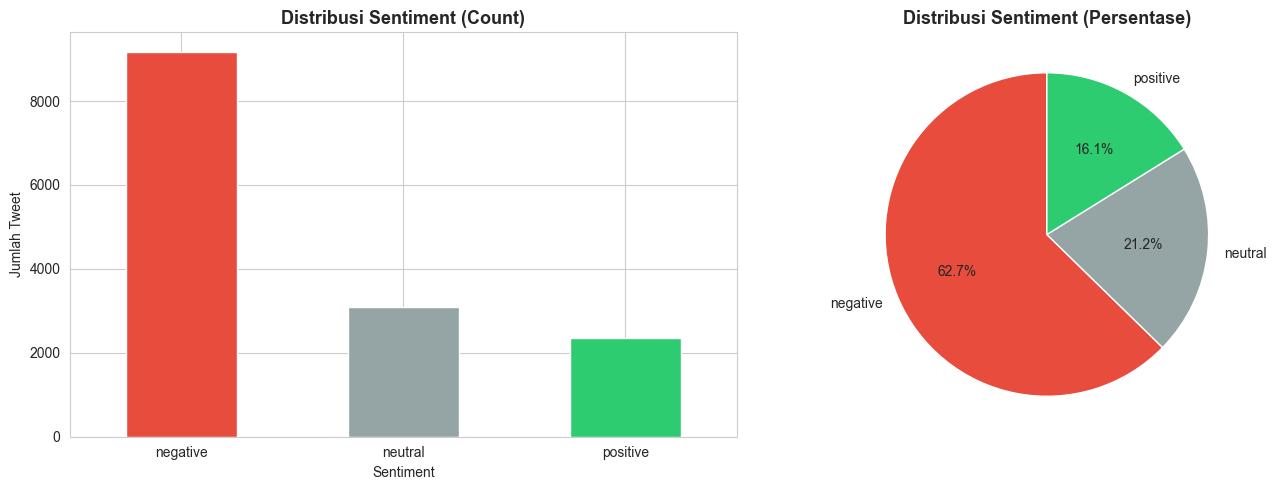

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = {'positive': '#2ecc71', 'neutral': '#95a5a6', 'negative': '#e74c3c'}
sentiment_counts.plot(kind='bar', ax=ax[0], color=[colors[s] for s in sentiment_counts.index])
ax[0].set_title('Distribusi Sentiment (Count)', fontsize=13, fontweight='bold')
ax[0].set_xlabel('Sentiment')
ax[0].set_ylabel('Jumlah Tweet')
ax[0].tick_params(axis='x', rotation=0)

# Pie chart
ax[1].pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%',
          colors=[colors[s] for s in sentiment_counts.index], startangle=90)
ax[1].set_title('Distribusi Sentiment (Persentase)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight (Q1):** **62,7%** tweet bernada negatif, sementara positif hanya **16,1%**. Twitter dipakai pelanggan terutama sebagai kanal komplain, jadi tim social care perlu siap menangani volume keluhan yang tinggi.

*Catatan teknis:* data ini **imbalanced** (kelas negatif dominan), sehingga saat pemodelan perlu ditangani agar model tidak bias ke kelas negatif.

## 6. Distribusi per Airline

Maskapai mana yang paling banyak dibahas?

In [8]:
airline_counts = df['airline'].value_counts()
print(airline_counts)

airline
United            3822
US Airways        2913
American          2759
Southwest         2420
Delta             2222
Virgin America     504
Name: count, dtype: int64


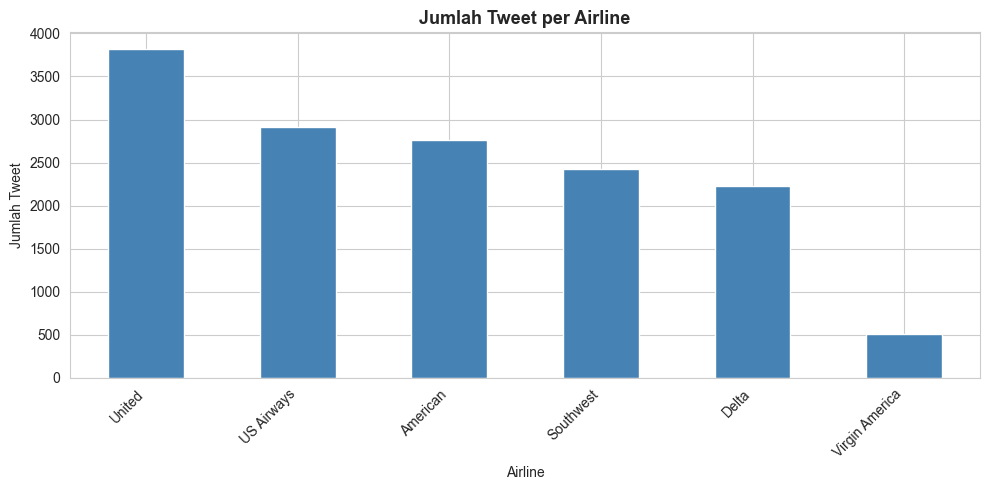

In [9]:
plt.figure(figsize=(10, 5))
airline_counts.plot(kind='bar', color='steelblue')
plt.title('Jumlah Tweet per Airline', fontsize=13, fontweight='bold')
plt.xlabel('Airline')
plt.ylabel('Jumlah Tweet')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 7. Sentiment per Airline

Airline mana yang paling banyak komplennya? Yang paling banyak dipuji?

In [10]:
sentiment_per_airline = pd.crosstab(df['airline'], df['airline_sentiment'], normalize='index') * 100
sentiment_per_airline = sentiment_per_airline[['negative', 'neutral', 'positive']]
sentiment_per_airline = sentiment_per_airline.sort_values('negative', ascending=False)
sentiment_per_airline.round(1)

airline_sentiment,negative,neutral,positive
airline,,,
US Airways,77.7,13.1,9.2
American,71.0,16.8,12.2
United,68.9,18.2,12.9
Southwest,49.0,27.4,23.6
Delta,43.0,32.5,24.5
Virgin America,35.9,33.9,30.2


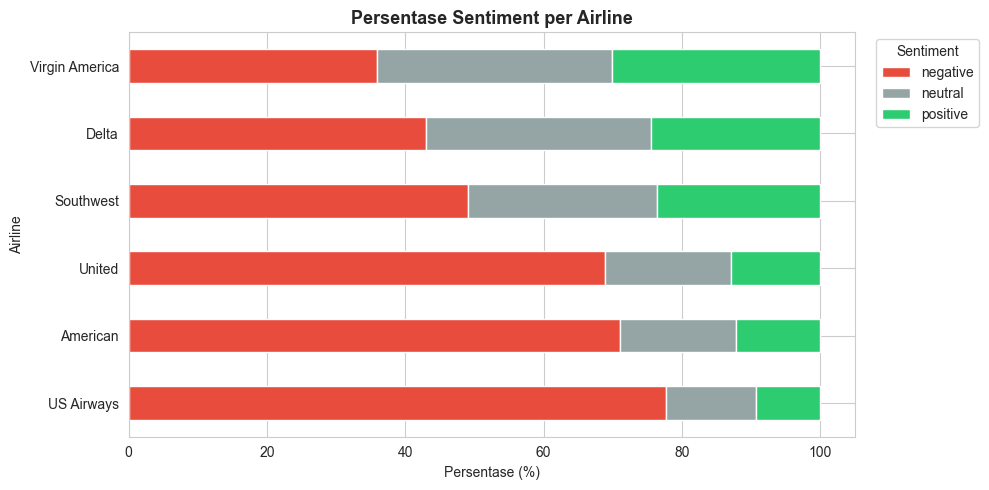

In [11]:
sentiment_per_airline.plot(kind='barh', stacked=True, figsize=(10, 5),
                            color=['#e74c3c', '#95a5a6', '#2ecc71'])
plt.title('Persentase Sentiment per Airline', fontsize=13, fontweight='bold')
plt.xlabel('Persentase (%)')
plt.ylabel('Airline')
plt.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Insight (Q2):**
- **US Airways** paling buruk: **77,7%** tweet-nya negatif dan hanya 9,2% positif, disusul **American** (71,0%) dan **United** (68,9%).
- **Virgin America** paling baik (35,9% negatif, 30,2% positif), disusul **Delta** (43,0%) dan **Southwest** (49,0%).
- Selisih maskapai terbaik dan terburuk mencapai **~42 poin persentase** — jadi reputasi buruk bukan "nasib industri", tapi berbeda nyata antar maskapai.
- United, US Airways, dan American menyumbang ~65% volume tweet, tetapi **~75% dari seluruh tweet negatif**.

## 8. Alasan Komplen Negatif

Kalau orang ngomel di Twitter, paling banyak ngomel soal apa?

In [12]:
negative_reasons = df[df['airline_sentiment'] == 'negative']['negativereason'].value_counts()
negative_reasons

negativereason
Customer Service Issue         2910
Late Flight                    1665
Can't Tell                     1190
Cancelled Flight                847
Lost Luggage                    724
Bad Flight                      580
Flight Booking Problems         529
Flight Attendant Complaints     481
longlines                       178
Damaged Luggage                  74
Name: count, dtype: int64

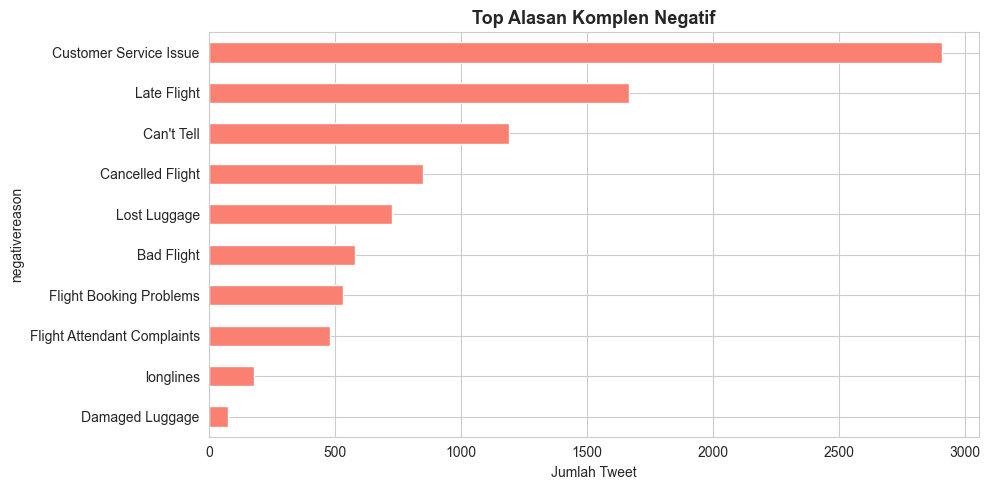

In [13]:
plt.figure(figsize=(10, 5))
negative_reasons.plot(kind='barh', color='salmon')
plt.title('Top Alasan Komplen Negatif', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Tweet')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Insight (Q3):**
- **Customer Service Issue** adalah pemicu keluhan terbesar: **31,7%** dari tweet negatif — hampir dua kali lipat **Late Flight** (18,1%).
- Masalah **operasional** (Late Flight + Cancelled Flight) gabungan menyumbang **27,4%**, masih lebih kecil dari masalah layanan pelanggan.
- Masalah **bagasi** (Lost + Damaged Luggage) menyumbang **8,7%**.
- **13,0%** keluhan berlabel *Can't Tell* — alasannya tidak bisa ditentukan dari teks tweet saja.

Artinya: keluhan yang paling sering bukan soal pesawat terlambat, tapi soal **bagaimana pelanggan dilayani** — dan itu lebih bisa dikendalikan oleh maskapai daripada cuaca atau kepadatan bandara.

## 9. Analisis Panjang Tweet

Apakah tweet negatif cenderung lebih panjang dari positif?

In [14]:
df['text_length'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

df.groupby('airline_sentiment')[['text_length', 'word_count']].mean().round(1)

,text_length,word_count
airline_sentiment,,
negative,113.9,19.7
neutral,87.4,14.4
positive,86.1,14.0


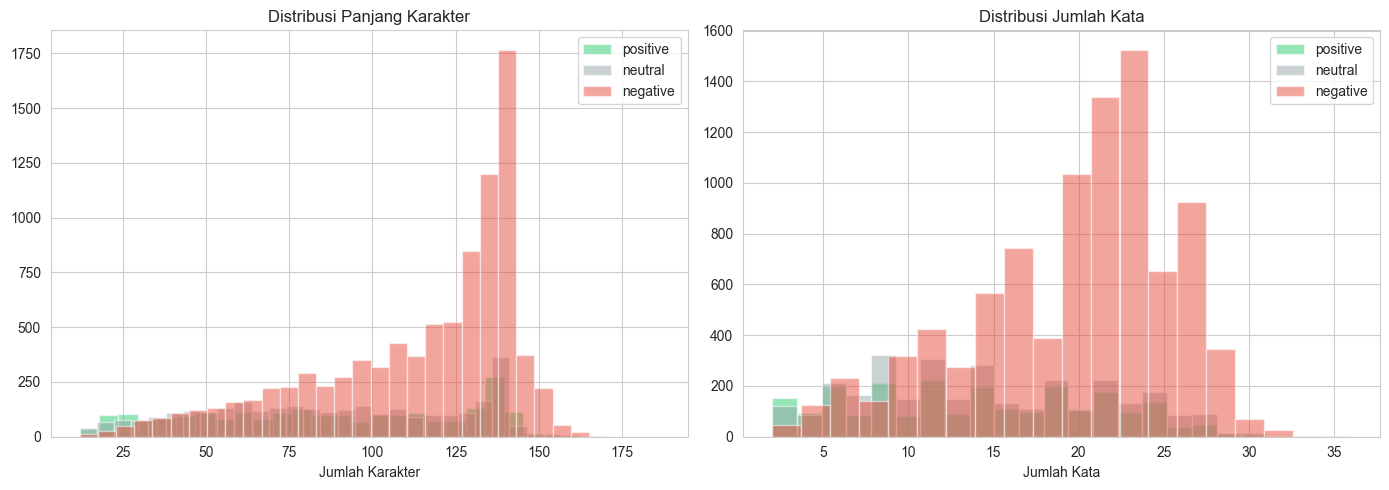

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for sentiment in ['positive', 'neutral', 'negative']:
    subset = df[df['airline_sentiment'] == sentiment]
    ax[0].hist(subset['text_length'], bins=30, alpha=0.5, label=sentiment, color=colors[sentiment])
    ax[1].hist(subset['word_count'], bins=20, alpha=0.5, label=sentiment, color=colors[sentiment])

ax[0].set_title('Distribusi Panjang Karakter')
ax[0].set_xlabel('Jumlah Karakter')
ax[0].legend()

ax[1].set_title('Distribusi Jumlah Kata')
ax[1].set_xlabel('Jumlah Kata')
ax[1].legend()

plt.tight_layout()
plt.show()

**Insight:** Tweet negatif rata-rata lebih panjang (**113,9 karakter / 19,7 kata**) dibanding netral (87,4) dan positif (86,1). Pelanggan yang kecewa cenderung menceritakan kronologi masalahnya — informasi yang berguna bagi tim social care untuk menindaklanjuti kasus.

## 10. Contoh Tweet per Sentiment

Biar dapet feel-nya, kita lihat sample tweet asli dari tiap kategori.

In [16]:
print("=" * 80)
print("🟢 POSITIVE TWEETS:")
print("=" * 80)
for tweet in df[df['airline_sentiment'] == 'positive']['text'].sample(3, random_state=42):
    print(f"• {tweet}")
    print()

print("=" * 80)
print("⚪ NEUTRAL TWEETS:")
print("=" * 80)
for tweet in df[df['airline_sentiment'] == 'neutral']['text'].sample(3, random_state=42):
    print(f"• {tweet}")
    print()

print("=" * 80)
print("🔴 NEGATIVE TWEETS:")
print("=" * 80)
for tweet in df[df['airline_sentiment'] == 'negative']['text'].sample(3, random_state=42):
    print(f"• {tweet}")
    print()

🟢 POSITIVE TWEETS:
• @SouthwestAir thanks for your excellent response time and assistance! All set :)

• @JetBlue thanks. I appreciate your prompt response.

• @JetBlue yes, with about 20 minutes to spare.  FYI - your employees are amazing.  Keep up the good work!

⚪ NEUTRAL TWEETS:
• @united we finally just arrive to Bogota, good but long flight!!

• @AmericanAir got a callback at 1 am, took care of it. thanks.

• @JetBlue is there wifi on he plain

🔴 NEGATIVE TWEETS:
• @united gate C 24 IAD. U released passengers to board w/others deplaning .50 peopleOn bridge while next flight  board http://t.co/HfoF33iyhi

• @USAirways 1729 connecting in charlotte to houston. Mechanical issue determined while q'd to take off. And we checked our bags.

• @united installed and working are not the same. Kicked me out after an hour and wouldn't let me back in. Four wasted hours.



## 11. Word Cloud

Kata-kata apa yang paling sering muncul di tiap sentiment?

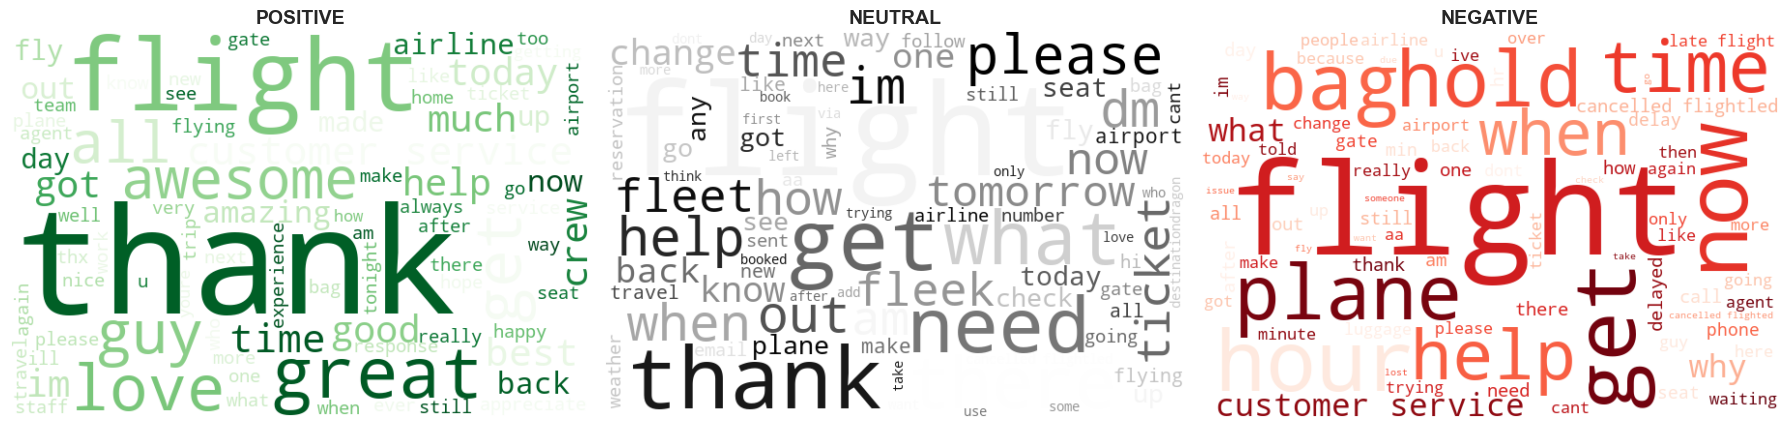

In [17]:
def clean_text_basic(text):
    """Pembersihan dasar buat word cloud."""
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)   # remove URLs
    text = re.sub(r'@\w+', '', text)               # remove mentions
    text = re.sub(r'#', '', text)                  # remove # but keep hashtag word
    text = re.sub(r'[^a-z\s]', '', text)           # keep only letters
    return text

# Stopwords sederhana
stopwords_basic = set(['the', 'a', 'an', 'is', 'are', 'was', 'were', 'be', 'been', 'being',
                      'i', 'you', 'he', 'she', 'it', 'we', 'they', 'them', 'us', 'me',
                      'my', 'your', 'his', 'her', 'its', 'our', 'their',
                      'to', 'of', 'in', 'on', 'at', 'for', 'with', 'by', 'from', 'about',
                      'and', 'or', 'but', 'if', 'so', 'as', 'that', 'this', 'these', 'those',
                      'have', 'has', 'had', 'do', 'does', 'did', 'will', 'would', 'could',
                      'should', 'can', 'just', 'not', 'no', 'yes', 'rt', 'amp',
                      # nama airline jangan ikut dihitung biar gak dominan
                      'united', 'usairways', 'americanair', 'southwestair', 'jetblue', 'virginamerica',
                      'us', 'airways', 'american', 'southwest'])

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, sentiment in enumerate(['positive', 'neutral', 'negative']):
    text_combined = ' '.join(df[df['airline_sentiment'] == sentiment]['text'].apply(clean_text_basic))
    
    wc = WordCloud(width=600, height=400, background_color='white',
                   stopwords=stopwords_basic, max_words=80,
                   colormap='Greens' if sentiment == 'positive' 
                           else 'Greys' if sentiment == 'neutral' else 'Reds').generate(text_combined)
    
    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(f'{sentiment.upper()}', fontsize=14, fontweight='bold')
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## 12. Kesimpulan, Rekomendasi & Keterbatasan

### 📌 Jawaban pertanyaan bisnis

| Pertanyaan | Jawaban |
|---|---|
| **Q1** Seberapa negatif percakapannya? | **62,7%** tweet negatif, hanya 16,1% positif. Twitter dipakai terutama sebagai kanal komplain. |
| **Q2** Maskapai terburuk & terbaik? | Terburuk **US Airways** (77,7% negatif), lalu American (71,0%) dan United (68,9%). Terbaik **Virgin America** (35,9%), lalu Delta (43,0%). |
| **Q3** Pemicu utama keluhan? | **Customer Service Issue (31,7%)**, lebih besar dari gabungan Late + Cancelled Flight (27,4%). |

### 💡 Rekomendasi (Q4)

1. **Prioritaskan perbaikan layanan pelanggan, bukan hanya ketepatan waktu.** Pemicu keluhan terbesar (31,7%) adalah customer service — area yang paling bisa dikendalikan maskapai (pelatihan staf, waktu respons, kewenangan agen untuk memberi solusi).
2. **Fokuskan sumber daya social care ke United, US Airways, dan American.** Ketiganya menghasilkan ~75% tweet negatif; perbaikan di sini berdampak paling besar terhadap sentimen industri secara keseluruhan.
3. **Kirim notifikasi proaktif saat delay/pembatalan.** Keluhan operasional (27,4%) sulit dihindari, tapi informasi yang cepat dan opsi rebooking otomatis bisa mencegah keluhan berlanjut menjadi keluhan layanan.
4. **Pelajari praktik Virgin America dan Delta.** Porsi tweet positif mereka (30,2% dan 24,5%) sekitar 2–3× US Airways (9,2%) — layak dijadikan benchmark.
5. **Pantau sentimen secara otomatis.** Model klasifikasi di notebook 03 dapat menandai tweet negatif untuk ditindaklanjuti tim social care secara real-time, alih-alih membaca semua tweet secara manual.

### ⚠️ Keterbatasan data
- Data hanya mencakup **~1 minggu di Februari 2015** — pola musiman dan kondisi terkini tidak tercermin.
- Pengguna Twitter yang menulis tentang maskapai **cenderung yang sedang punya masalah**, jadi porsi negatif kemungkinan lebih tinggi daripada kepuasan pelanggan sebenarnya.
- Alasan keluhan (`negativereason`) adalah label annotator, dan 13% tidak bisa ditentukan (*Can't Tell*).
- Sebagian tweet berlabel **Delta** ternyata menyebut **@JetBlue** (terlihat di contoh tweet dan word cloud), sehingga angka "Delta" perlu diverifikasi sebelum dijadikan benchmark.
- Volume tweet per maskapai tidak dinormalisasi terhadap jumlah penumpang, jadi analisis memakai **persentase**, bukan jumlah absolut.

### 🚀 Langkah berikutnya
- **Notebook 02 — Preprocessing:** membersihkan teks tweet untuk pemodelan.
- **Notebook 03–04 — Modeling & Evaluation:** membangun model klasifikasi sentimen untuk pemantauan otomatis.
- **Dashboard Streamlit:** menyajikan insight di atas secara interaktif.

### 💾 Simpan data untuk notebook berikutnya:

In [18]:
# Drop kolom yang missing-nya tinggi & gak kepake
df_clean = df.drop(columns=['airline_sentiment_gold', 'negativereason_gold', 'tweet_coord'])
df_clean.to_csv('../data/processed/tweets_eda.csv', index=False)
print(f"✅ Saved to data/processed/tweets_eda.csv")
print(f"   Shape: {df_clean.shape}")

✅ Saved to data/processed/tweets_eda.csv
   Shape: (14640, 14)
